# GVH Diagonal Cubic — Hierarchical Internal Activity & Conservation Gate (FAST)

**Mission.** Formaliser et éprouver l'idée qu'un « cube » peut avoir une **activité interne importante** tout en conservant une masse totale pratiquement constante. Un changement d'échelle peut masquer les cycles et la dissipation sans faire disparaître physiquement ces phénomènes.

### Architecture obligatoire
1. **Niveau 1 — GVH** : classification *actif / dormant / relativement inactif*, hypothèse de variables effectives internes.
2. **Niveau 2 — physique établie** : bilans de masse et d'énergie des systèmes ouverts/fermés, réduction de modèle.
3. **Niveau 3 — test numérique minimal** : trois compartiments en circulation ; vérification des bilans, état interne invisible après agrégation, temps modaux.
4. **Niveau 4 — verdict scientifique** : PASS d'audit local ≠ équations du mouvement GVH démontrées.

**Attention.** « Actif » est **physique/dynamique**, jamais synonyme de vie biologique. Les valeurs du modèle sont **fictives et prescrites**, et aucune donnée terrestre ne sert de calibration. Le modèle n'est ni une équation GVH dérivée, ni une nouvelle théorie thermodynamique.

**Documents amont :** `GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_EXECUTED` et `GVH_Hierarchical_Cube_Quadrupole_Frequency_Gate_FAST_EXECUTED` ; cohérence avec les verrous `.3.3.27.3/.3.3.27.4/.3.3.28`.

In [1]:
from __future__ import annotations
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.constants import day

NOTEBOOK = "GVH_Hierarchical_Internal_Activity_Conservation_Gate_FAST"
ROOT = Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()

PROVENANCE = {}
for stem in (
 'GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_EXECUTED.ipynb',
 'GVH_Action_Candidate_Two_Cube_Shear_Overlap_Gate_FAST_results.json',
 'GVH_Hierarchical_Cube_Quadrupole_Frequency_Gate_FAST_EXECUTED.ipynb',
):
 p=ROOT/stem
 PROVENANCE[stem]={'present_in_this_runtime':p.exists(), 'sha256':hashlib.sha256(p.read_bytes()).hexdigest() if p.exists() else None}
print('Python:',sys.version.split()[0])
print('Source files detected locally:',sum(v['present_in_this_runtime'] for v in PROVENANCE.values()))
print('Optional upstream files are NOT required to execute this notebook.')

Python: 3.13.5
Source files detected locally: 3
Optional upstream files are NOT required to execute this notebook.


# Niveau 1 — GVH : proposition de classification

On représente un cube d'observation par un ensemble de réservoirs de matière $m_i$ et de **flux internes** $J_{ij}\ge0$. La variable $M_C=\sum_i m_i$ ne suffit généralement pas à connaître l'activité interne. On propose comme **indicateur opérationnel de jouet** :

$$A_C(t)=\sum_{(i,j)\in E_C}J_{ij}(t)\qquad [A_C]={\rm kg\,s^{-1}}.$$

Ce débit brut n'est **pas** une loi universelle d'activité ou une mesure de vie : il dépend des compartiments et du graphe retenus. Il mesure ici l'intensité des transferts, non leur bilan net ni la dissipation thermodynamique.

Le modèle à trois compartiments est un cycle dirigé : $1\to2\to3\to1$. Les flux sont $J_{12}=k_{12}m_1$, $J_{23}=k_{23}m_2$, $J_{31}=k_{31}m_3$. Les coefficients $k$ sont **prescrits** (unité $\rm s^{-1}$), **pas dérivés de GVH**.

Le même modèle peut fonctionner en **système fermé** (flux d'entrée et sortie nuls) ou en **système ouvert** (apports/retraits explicites à la frontière).

In [2]:
J12, J23, J31, I, O = sp.symbols('J12 J23 J31 I O', real=True)
dm = sp.Matrix([-J12 + J31 + I, J12 - J23, J23 - J31 - O])
G_ACTIVITY_MASS_CONTINUITY_IDENTITY = sp.simplify(sum(dm) - (I-O)) == 0
assert G_ACTIVITY_MASS_CONTINUITY_IDENTITY
print('Sum of compartment mass derivatives =',sp.simplify(sum(dm)))
print('G_ACTIVITY_MASS_CONTINUITY_IDENTITY =',G_ACTIVITY_MASS_CONTINUITY_IDENTITY)

Sum of compartment mass derivatives = I - O
G_ACTIVITY_MASS_CONTINUITY_IDENTITY = True


# Niveau 2 — Physique établie

### Continuité de la masse (limite classique)

$$\frac{dM_C}{dt}=\dot M_{\rm in}-\dot M_{\rm out}.$$

Les flux *internes* disparaissent exactement du bilan de la masse *totale* ; les flux à la frontière ne disparaissent pas. En contexte relativiste, un bilan complet doit prendre en compte l'énergie et la masse-énergie.

### Énergie : comptabilité de jouet en système fermé

Une quantité d'énergie de réserve $E_{\rm stock}$ est transformée en énergie thermique **conservée à l'intérieur de la frontière du cube** :

$$P_{\rm diss}(t)=\sum_{ij}\epsilon_{ij}J_{ij}(t),\qquad
\dot E_{\rm stock}=-P_{\rm diss},\quad\dot E_{\rm thermique}=P_{\rm diss}.$$

Ici $\epsilon_{ij}$ sont des coûts énergétiques **prescrits** (J/kg). Le terme de transfert d'énergie n'est **pas** une dérivation thermodynamique microscopique et ne prétend pas mesurer la production d'entropie. La circulation ne peut pas être prolongée indéfiniment avec une réserve finie : le modèle est uniquement utilisé sur une fenêtre de temps où $E_{\rm stock}>0$.

### Travaux scientifiques pertinents (recherchés avec Scite)

- Kawaguchi (2015), *Invariance of steady-state thermodynamics between different scales of description*, Physical Review E, DOI: [10.1103/PhysRevE.91.012115](https://doi.org/10.1103/PhysRevE.91.012115). Les variables thermodynamiques conservées par un changement de résolution requièrent des conditions ; tout n'est pas invariant.
- Kawaguchi et Nakagawa (2018), *Unattainability of Carnot efficiency in thermal motors: Coarse graining and entropy production of Feynman-Smoluchowski ratchets*, Physical Review E, DOI: [10.1103/PhysRevE.98.022102](https://doi.org/10.1103/PhysRevE.98.022102). Une description coarse-grained peut masquer de la dissipation.

Les résultats de ce notebook restent un *benchmark élémentaire*, non une nouvelle conséquence de ces publications.

In [3]:
D = float(day)  # exact number of seconds in a SI day = 86400
M0 = np.array([250.,350.,400.])  # toy kilograms
E0 = 5.0e8  # joules, toy reserve
EPS_J_PER_KG = np.array([5_000.,7_000.,9_000.])
RATES_ACTIVE_PER_DAY = np.array([0.40,0.25,0.16])
OBS_DAYS = 30
SAMPLE_DAYS = np.linspace(0.,OBS_DAYS,601)
T_EVAL = SAMPLE_DAYS*D


def integrate_case(rate_multiplier=1., input_kg_day=0., output_kg_day=0., with_energy=True):
    k = (RATES_ACTIVE_PER_DAY/D)*rate_multiplier
    inlet = input_kg_day / D
    outlet = output_kg_day / D
    # y=[m1,m2,m3,E_stock,E_heat,H_cumulative, B_cumulative]
    y0=np.array([*M0, E0,0.,0.,0.],dtype=float)
    def deriv(t,y):
        m1,m2,m3=y[:3]
        j=np.array([k[0]*m1,k[1]*m2,k[2]*m3])
        p=float(EPS_J_PER_KG@j) if with_energy else 0.
        return np.array([-j[0]+j[2]+inlet, j[0]-j[1], j[1]-j[2]-outlet,
                         -p,p,float(j.sum()),inlet-outlet])
    sol=solve_ivp(deriv,(0,OBS_DAYS*D),y0,method='DOP853',t_eval=T_EVAL,
                  rtol=1e-11,atol=1e-10)
    assert sol.success, sol.message
    m=sol.y[:3,:]
    js=k[:,None]*m
    return dict(sol=sol, masses=m, total=m.sum(axis=0),
                throughput_kg_day=js.sum(axis=0)*D,
                energy_total=sol.y[3,:]+sol.y[4,:],
                reserve=sol.y[3,:],heat=sol.y[4,:],
                cumulative_internal_mass=sol.y[5,:],
                net_external_mass=sol.y[6,:],
                incoming_kg_day=input_kg_day,outgoing_kg_day=output_kg_day,
                rates_per_day=(RATES_ACTIVE_PER_DAY*rate_multiplier).tolist())

ACTIVE=integrate_case(1.0)
DORMANT=integrate_case(0.01)
INACTIVE=integrate_case(0.0)
OPEN=integrate_case(1.0,input_kg_day=0.3,output_kg_day=0.1,with_energy=False)
print('test scenarios integrated:', ['active','dormant','inactive','open'])

test scenarios integrated: ['active', 'dormant', 'inactive', 'open']


# Niveau 3 — Test numérique minimal

Les paramètres suivants sont **fictifs** ; ils ne représentent ni la Terre, ni la Lune, ni un volcan. Les trois modèles ont les mêmes masses initiales ($M_0=1000$ kg) ; seuls les coefficients internes diffèrent : actif $k$, dormant $0{,}01k$, inactif $k=0$. Dans le test ouvert, $0{,}3$ kg/j arrive et $0{,}1$ kg/j sort.

La précision des bilans doit être vérifiée avec une **tolérance numérique fixée avant l'inspection des résultats**. Nous exigeons $10^{-7}$ kg d'erreur absolue sur les masses conservées et $10^{-3}$ J sur le bilan fermé d'énergie. Aucune valeur n'est ajustée sur une observation.

In [4]:
MASS_TOL_KG=1e-7
ENERGY_TOL_J=1e-3
rows=[]
for name,r in [('ACTIF',ACTIVE),('DORMANT',DORMANT),('INACTIF',INACTIVE),('OUVERT',OPEN)]:
    sol=r['sol']; M=r['total']
    expected_mass=M0.sum()+r['net_external_mass']
    mass_error=float(np.max(np.abs(M-expected_mass)))
    energy_error=(float(np.max(np.abs(r['energy_total']-E0))) if name!='OUVERT' else None)
    residual_energy_ok=energy_error is None or energy_error < ENERGY_TOL_J
    stock_positive=bool(np.min(r['reserve'])>0) if name!='OUVERT' else True
    positivity=bool(np.min(r['masses'])>=-1e-10)
    mass_ok=mass_error<MASS_TOL_KG
    assert mass_ok and residual_energy_ok and stock_positive and positivity
    rows.append(dict(scenario=name, initial_mass_kg=float(M[0]),final_mass_kg=float(M[-1]),
       initial_activity_kg_per_day=float(r['throughput_kg_day'][0]),
       final_activity_kg_per_day=float(r['throughput_kg_day'][-1]),
       cumulative_processed_mass_kg=float(r['cumulative_internal_mass'][-1]),
       max_mass_balance_error_kg=mass_error,
       max_energy_balance_error_J=energy_error,
       minimum_energy_stock_J=float(np.min(r['reserve'])) if name!='OUVERT' else None))
RESULTS_TABLE=pd.DataFrame(rows)
G_NUMERIC_CONTINUITY_PASS=bool(all(x['max_mass_balance_error_kg']<MASS_TOL_KG for x in rows))
G_NUMERIC_ENERGY_PASS=bool(all((x['max_energy_balance_error_J'] or 0.)<ENERGY_TOL_J for x in rows))
assert G_NUMERIC_CONTINUITY_PASS and G_NUMERIC_ENERGY_PASS
print(RESULTS_TABLE.to_string(index=False))

scenario  initial_mass_kg  final_mass_kg  initial_activity_kg_per_day  final_activity_kg_per_day  cumulative_processed_mass_kg  max_mass_balance_error_kg  max_energy_balance_error_J  minimum_energy_stock_J
   ACTIF           1000.0         1000.0                      251.500                 235.294207                   7086.332003               2.273737e-13                1.192093e-07            4.505035e+08
 DORMANT           1000.0         1000.0                        2.515                   2.493674                     75.124098               1.136868e-13                5.960464e-08            4.994942e+08
 INACTIF           1000.0         1000.0                        0.000                   0.000000                      0.000000               0.000000e+00                0.000000e+00            5.000000e+08
  OUVERT           1000.0         1006.0                      251.500                 236.825002                   7110.885909               2.273737e-13                       

## Test central : l'agrégation peut cacher l'activité

Les trois cubes fermés ont **exactement la même masse totale**. Une représentation effective qui ne conserve que $M_C$ est donc incapable de distinguer un cube actif, un dormant et un inactif.

Une variable effective $A_C$ peut préserver *une information* sur les flux internes ; elle ne suffit toutefois pas toujours à reconstruire toute la dynamique microscopique. C'est une **possibilité de modélisation**, non un degré de liberté GVH dérivé.

In [5]:
same_M0=all(abs(r['total'][0]-ACTIVE['total'][0])<1e-12 for r in [DORMANT,INACTIVE])
different_A0=(ACTIVE['throughput_kg_day'][0]>
              DORMANT['throughput_kg_day'][0]>
              INACTIVE['throughput_kg_day'][0])
G_SAME_MASS_DIFFERENT_INTERNAL_ACTIVITY_PASS=bool(same_M0 and different_A0)
assert G_SAME_MASS_DIFFERENT_INTERNAL_ACTIVITY_PASS
print('M(0) for each closed scenario (kg):',*[x['total'][0] for x in [ACTIVE,DORMANT,INACTIVE]])
print('A(0) (kg/day) active/dormant/inactive:',*[x['throughput_kg_day'][0] for x in [ACTIVE,DORMANT,INACTIVE]])
print('Same mass; different internal turnover =',G_SAME_MASS_DIFFERENT_INTERNAL_ACTIVITY_PASS)

M(0) for each closed scenario (kg): 1000.0 1000.0 1000.0
A(0) (kg/day) active/dormant/inactive: 251.5 2.5149999999999997 0.0
Same mass; different internal turnover = True


## Les fréquences internes ne sont pas universelles

Pour un cycle à trois transitions de **même taux** $k$, la matrice linéaire de transfert a un mode conservé et deux modes amortis :

$$\lambda_0=0,\qquad \lambda_\pm=-\frac{3k}{2}\pm i\frac{\sqrt3 k}{2}.$$

La fréquence modale $f_{\rm mode}=\lvert\operatorname{Im}\lambda\rvert/(2\pi)$ est **une conséquence des taux choisis**, avec amortissement rapide. Ce n'est ni une oscillation persistante de la Terre, ni un pont planétaire–atomique, ni une fréquence imposée par l'action GVH.

In [6]:
k_day=0.35
K=k_day*np.array([[-1.,0.,1.],[1.,-1.,0.],[0.,1.,-1.]])
eigs=np.linalg.eigvals(K)
expected=np.array([0.,-1.5*k_day+1j*np.sqrt(3)*k_day/2,
                      -1.5*k_day-1j*np.sqrt(3)*k_day/2])
G_MODAL_EIGEN_IDENTITY_PASS=bool(np.max(np.abs(np.sort_complex(eigs)-np.sort_complex(expected)))<1e-12)
assert G_MODAL_EIGEN_IDENTITY_PASS
modal_freq_hz=float((np.sqrt(3)*k_day/2)/(2*np.pi*D))
damping_time_days=1/(1.5*k_day)
modal_period_days=1/(modal_freq_hz*D)
print('Modal frequency:',modal_freq_hz,'Hz (rate prescribed)')
print('Damping time:',damping_time_days,'days')
print('Modal period:',modal_period_days,'days')

Modal frequency: 5.583481290440601e-07 Hz (rate prescribed)
Damping time: 1.904761904761905 days
Modal period: 20.72913559124821 days


## Tracés de vérification

On doit visualiser **à la fois** la masse conservée et les débits internes ; un graphe de masse seul cacherait l'activité. Pour le système ouvert, la variation totale doit être égale à l'apport net connu par intégration. Le graphique n'est pas un instrument de validation GVH indépendant.

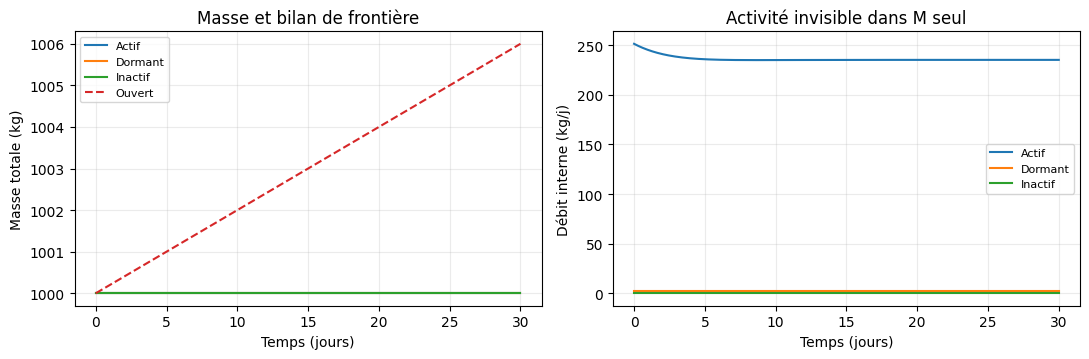

In [7]:
import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,2,figsize=(11,3.7))
for name,r in [('Actif',ACTIVE),('Dormant',DORMANT),('Inactif',INACTIVE)]:
    axs[0].plot(SAMPLE_DAYS,r['total'],label=name)
    axs[1].plot(SAMPLE_DAYS,r['throughput_kg_day'],label=name)
axs[0].plot(SAMPLE_DAYS,OPEN['total'],ls='--',label='Ouvert')
axs[0].set(xlabel='Temps (jours)',ylabel='Masse totale (kg)',title='Masse et bilan de frontière')
axs[1].set(xlabel='Temps (jours)',ylabel='Débit interne (kg/j)',title='Activité invisible dans M seul')
for ax in axs: ax.legend(fontsize=8); ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

# Niveau 4 — Verdict scientifique

- **PASS (physique établie)** : continuité de la masse, conservation interne de l'énergie dans le jouet fermé, bilan ouvert, modes linéaires.
- **PASS (démonstration méthodologique)** : une même masse globale peut cacher plusieurs niveaux de circulation de matière ; le cube effectif doit préserver davantage que $M_C$ si l'on souhaite prédire son activité.
- **NON démontré** : définition universelle de $A_C$ ; dynamique interne à partir de $S_{\rm cand}$ ; couplage GVH matière–trièdre ; loi de fréquence inter-échelles ; choix des taux / constantes SI par GVH ; nouvelle physique validée.

**Prochain verrou scientifique autorisé :** définir un opérateur de réduction et une source de matière dans l'action candidate, puis dériver l'évolution d'un *observable d'activité* et une correction testable sur un système à plusieurs échelles — sans réajuster les couplages sur l'observable testé.

In [8]:
LEVEL1_GVH='HIERARCHICAL_INTERNAL_ACTIVITY_PROPOSED_NOT_EOM_DERIVED'
LEVEL2_ESTABLISHED='CONTINUITY_AND_ENERGY_BOOKKEEPING_CONSISTENT'
LEVEL3_NUMERICAL='MINIMAL_NUMERIC_WITNESS_PASS'
LEVEL4_SCIENTIFIC='ESTABLISHED_BENCHMARK_PASS__GVH_ACTIVITY_DYNAMICS_BLOCKED'
LOCKS={
 'GVH_internal_activity_operator_derived':False,
 'GVH_mass_transport_rates_derived':False,
 'GVH_matter_coupling_from_S_cand_derived':False,
 'GVH_independent_SI_scale_derived':False,
 'GVH_micro_macro_frequency_relation_derived':False,
 'new_GVH_physics_validated':False,
}
LOCAL_AUDIT_PASS=all([
 G_ACTIVITY_MASS_CONTINUITY_IDENTITY,
 G_NUMERIC_CONTINUITY_PASS,
 G_NUMERIC_ENERGY_PASS,
 G_SAME_MASS_DIFFERENT_INTERNAL_ACTIVITY_PASS,
 G_MODAL_EIGEN_IDENTITY_PASS,
 not any(LOCKS.values()),
])
assert LOCAL_AUDIT_PASS
SUMMARY={
 'notebook':NOTEBOOK,
 'classification':'SUPPLEMENTARY_NONCANONICAL_FOUR_LEVEL_AUDIT',
 'four_levels':{'GVH':LEVEL1_GVH,'established_physics':LEVEL2_ESTABLISHED,
                'minimal_numeric_test':LEVEL3_NUMERICAL,'scientific_verdict':LEVEL4_SCIENTIFIC},
 'local_audit_pass':bool(LOCAL_AUDIT_PASS),
 'parameter_policy':{'all_rates_prescribed':True,'energy_costs_prescribed':True,
                     'no_observed_planet_data_used_for_fit':True,'SI_units_are_defined':True,
                     'no_absolute_scale_derived':True},
 'tolerance':{'mass_kg':MASS_TOL_KG,'energy_J':ENERGY_TOL_J},
 'tests':{
  'mass_continuity_symbolic':bool(G_ACTIVITY_MASS_CONTINUITY_IDENTITY),
  'mass_continuity_numeric':bool(G_NUMERIC_CONTINUITY_PASS),
  'energy_bookkeeping_closed':bool(G_NUMERIC_ENERGY_PASS),
  'same_mass_different_activity':bool(G_SAME_MASS_DIFFERENT_INTERNAL_ACTIVITY_PASS),
  'modal_eigen_identity':bool(G_MODAL_EIGEN_IDENTITY_PASS)},
 'scenarios':rows,
 'modal':{'prescribed_rate_per_day':k_day, 'frequency_Hz':modal_freq_hz,
          'damping_time_days':float(damping_time_days),'modal_period_days':float(modal_period_days)},
 'upstream_files_optional':PROVENANCE,
 'literature':[{'doi':'10.1103/PhysRevE.91.012115','role':'thermodynamic coarse-graining context'},
               {'doi':'10.1103/PhysRevE.98.022102','role':'hidden dissipation under coarse-graining'}],
 'locks':LOCKS,
 'next_authorized':'SOURCE_COUPLING_FROM_S_CAND_AND_DERIVE_ACTIVITY_OBSERVABLE_OR_REMAIN_BLOCKED',
}
jsonpath=ROOT/(NOTEBOOK+'_results.json')
jsonpath.write_text(json.dumps(SUMMARY,indent=2,ensure_ascii=False),encoding='utf-8')
print('LOCAL_AUDIT_PASS =',LOCAL_AUDIT_PASS)
print('LEVEL4_SCIENTIFIC =',LEVEL4_SCIENTIFIC)
print('Results JSON =',str(jsonpath))

LOCAL_AUDIT_PASS = True
LEVEL4_SCIENTIFIC = ESTABLISHED_BENCHMARK_PASS__GVH_ACTIVITY_DYNAMICS_BLOCKED
Results JSON = /mnt/data/GVH_Hierarchical_Internal_Activity_Conservation_Gate_FAST_results.json
